# Data Audit: VitaminC

This notebook validates the datasets used to evaluate LLM fact-checkers.

## Objectives

1. Confirm that all required files are available.
2. Understand each dataset's structure.
3. Examine label distributions.
4. Detect missing, duplicated or malformed records.
5. Verify that processed samples match their original sources.
6. Document any data-quality limitations before modelling.

This notebook is read-only and does not modify the original datasets.

In [12]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import os

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Data-audit environment is ready.")
print(f"Pandas version: {pd.__version__}")

Data-audit environment is ready.
Pandas version: 2.2.2


In [13]:
# Locate the repository root.
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Prefer the repository data location.
repository_train_path = (
    PROJECT_ROOT
    / "data/vitaminc/raw/vitaminc/train.jsonl"
)

# Temporary fallback to the downloaded dataset.
downloads_train_path = (
    Path.home()
    / "Downloads/vitaminc/raw/vitaminc/train.jsonl"
)

if repository_train_path.exists():
    VITAMINC_TRAIN_PATH = repository_train_path
elif downloads_train_path.exists():
    VITAMINC_TRAIN_PATH = downloads_train_path
else:
    raise FileNotFoundError(
        "VitaminC train.jsonl was not found in the repository "
        "or Downloads folder."
    )

vitaminc_train_df = pd.read_json(
    VITAMINC_TRAIN_PATH,
    lines=True,
)

print(f"Source: {VITAMINC_TRAIN_PATH}")
print(f"Rows: {len(vitaminc_train_df):,}")
print(f"Columns: {vitaminc_train_df.shape[1]}")
print(f"Column names: {vitaminc_train_df.columns.tolist()}")

Source: /Users/shameelzeshan/Downloads/vitaminc/raw/vitaminc/train.jsonl
Rows: 370,653
Columns: 9
Column names: ['unique_id', 'case_id', 'wiki_revision_id', 'label', 'claim', 'evidence', 'page', 'revision_type', 'FEVER_id']


## Schema and Data Completeness Audit

This audit examines the structure and completeness of the VitaminC training dataset. For each column, it reports:

- the inferred pandas data type;
- the number of populated and missing rows;
- the percentage of missing values; and
- the number of distinct non-null values.

Missing values are not automatically data-quality problems. VitaminC combines real Wikipedia revisions and synthetic FEVER examples, which use different source identifiers. The audit therefore distinguishes expected structural missingness from missing values in essential fields such as the claim, evidence and label.

In [14]:
schema_summary = pd.DataFrame(
    {
        "column": vitaminc_train_df.columns,
        "data_type": [
            str(vitaminc_train_df[column].dtype)
            for column in vitaminc_train_df.columns
        ],
        "non_null_rows": [
            vitaminc_train_df[column].notna().sum()
            for column in vitaminc_train_df.columns
        ],
        "missing_rows": [
            vitaminc_train_df[column].isna().sum()
            for column in vitaminc_train_df.columns
        ],
        "missing_percentage": [
            vitaminc_train_df[column].isna().mean() * 100
            for column in vitaminc_train_df.columns
        ],
        "unique_values": [
            vitaminc_train_df[column].nunique(dropna=True)
            for column in vitaminc_train_df.columns
        ],
    }
)

display(
    schema_summary.style
    .format(
        {
            "non_null_rows": "{:,}",
            "missing_rows": "{:,}",
            "missing_percentage": "{:.2f}%",
            "unique_values": "{:,}",
        }
    )
    .hide(axis="index")
)

column,data_type,non_null_rows,missing_rows,missing_percentage,unique_values
unique_id,object,"370,653",0,0.00%,"370,653"
case_id,object,"370,653",0,0.00%,"112,426"
wiki_revision_id,float64,"248,953","121,700",32.83%,"74,414"
label,object,"370,653",0,0.00%,3
claim,object,"370,653",0,0.00%,"175,905"
evidence,object,"370,653",0,0.00%,"185,217"
page,object,"370,653",0,0.00%,"22,198"
revision_type,object,"370,653",0,0.00%,2
FEVER_id,float64,"121,700","248,953",67.17%,"25,751"


#### Observations

The VitaminC training split contains 370,653 records. All essential fact-verification fields (`unique_id`, `case_id`, `label`, `claim`, `evidence`, `page`, and `revision_type`) are complete, with no missing values.

Every `unique_id` is distinct, confirming that no two rows share the same row identifier. The smaller numbers of unique `case_id`, claim and evidence values are expected because VitaminC groups related evidence versions and verdicts into contrastive cases.

The missing values in the source-identifier columns are structural:

- 248,953 real Wikipedia records contain a `wiki_revision_id` but no `FEVER_id`.
- 121,700 synthetic records contain a `FEVER_id` but no `wiki_revision_id`.

Together, these groups account for all 370,653 records. Therefore, the missing source identifiers should not be imputed or used as a reason to remove rows. They identify two different data-generation processes.

Pandas represents the identifier columns as `float64` because they contain numeric values mixed with missing values. These columns are identifiers rather than continuous numerical features and should be treated as categorical or string values if they are used later.

Overall, the dataset is structurally complete for claim-evidence classification, and no row removal or missing-value imputation is required at this stage.

In [15]:
vitaminc_train_df.head()


,unique_id,case_id,wiki_revision_id,label,claim,evidence,page,revision_type,FEVER_id
0,5ec5598dc9e77c000842c3cd_1,5ec5598dc9e77c000842c3cd,925488060.0,SUPPORTS,"Manchester had a population of more than 540,000 in 2017 and was the 5th most populous English district .","Manchester ( ) is a major city and metropolitan borough in Greater Manchester , England , with a population of 545,5...",Manchester,real,NaN
1,5ec5598dc9e77c000842c3cd_2,5ec5598dc9e77c000842c3cd,925488060.0,NOT ENOUGH INFO,"Manchester had a population of more than 540,000 in 2017 and was the 5th most populous English district .","Manchester ( ) is a major city and metropolitan borough in Greater Manchester , England , with a population of 534,9...",Manchester,real,NaN
2,5ec5598dc9e77c000842c3cd_3,5ec5598dc9e77c000842c3cd,925488060.0,NOT ENOUGH INFO,"Manchester had a population of less than 540,000 in 2018 and was the 4th most populous English district .","Manchester ( ) is a major city and metropolitan borough in Greater Manchester , England , with a population of 545,5...",Manchester,real,NaN
3,5ec5598dc9e77c000842c3cd_4,5ec5598dc9e77c000842c3cd,925488060.0,SUPPORTS,"Manchester had a population of less than 540,000 in 2018 and was the 4th most populous English district .","Manchester ( ) is a major city and metropolitan borough in Greater Manchester , England , with a population of 534,9...",Manchester,real,NaN
4,5eb29887c9e77c0008d92ca0_1,5eb29887c9e77c0008d92ca0,813603278.0,NOT ENOUGH INFO,Traditional Chinese medicine is founded on less than 4000 years of Chinese medical practice .,"Traditional Chinese medicine ( TCM ; ) is a style of traditional medicine built on a foundation of more than 2,500 y...",Traditional Chinese medicine,real,NaN


## Source Composition and Identifier Validation

VitaminC combines examples from two sources: real Wikipedia revisions and synthetic examples derived from FEVER. This analysis compares the size and diversity of each source and verifies that each row contains the correct source identifier.

A valid real row should contain a `wiki_revision_id` and no `FEVER_id`. A valid synthetic row should contain a `FEVER_id` and no `wiki_revision_id`.

In [16]:
source_summary = (
    vitaminc_train_df
    .groupby("revision_type")
    .agg(
        rows=("unique_id", "size"),
        unique_cases=("case_id", "nunique"),
        unique_claims=("claim", "nunique"),
        wikipedia_ids=("wiki_revision_id", "count"),
        fever_ids=("FEVER_id", "count"),
    )
    .reset_index()
)

display(
    source_summary.style
    .format(
        {
            "rows": "{:,}",
            "unique_cases": "{:,}",
            "unique_claims": "{:,}",
            "wikipedia_ids": "{:,}",
            "fever_ids": "{:,}",
        }
    )
    .hide(axis="index")
)

real_identifier_errors = (
    (vitaminc_train_df["revision_type"] == "real")
    & (
        vitaminc_train_df["wiki_revision_id"].isna()
        | vitaminc_train_df["FEVER_id"].notna()
    )
).sum()

synthetic_identifier_errors = (
    (vitaminc_train_df["revision_type"] == "synthetic")
    & (
        vitaminc_train_df["FEVER_id"].isna()
        | vitaminc_train_df["wiki_revision_id"].notna()
    )
).sum()

identifier_checks = pd.DataFrame(
    {
        "validation_check": [
            "Invalid identifier pattern in real rows",
            "Invalid identifier pattern in synthetic rows",
        ],
        "error_count": [
            real_identifier_errors,
            synthetic_identifier_errors,
        ],
        "status": [
            "PASS" if real_identifier_errors == 0 else "FAIL",
            "PASS" if synthetic_identifier_errors == 0 else "FAIL",
        ],
    }
)

display(identifier_checks.style.hide(axis="index"))

revision_type,rows,unique_cases,unique_claims,wikipedia_ids,fever_ids
real,"248,953","82,001","123,021","248,953",0
synthetic,"121,700","30,425","52,926",0,"121,700"


validation_check,error_count,status
Invalid identifier pattern in real rows,0,PASS
Invalid identifier pattern in synthetic rows,0,PASS


### Findings

The training dataset contains two distinct source groups:

- **Real revisions:** 248,953 rows, representing approximately 67.17% of the training data.
- **Synthetic examples:** 121,700 rows, representing approximately 32.83% of the training data.

The real subset contains 82,001 unique cases and 123,021 unique claims, while the synthetic subset contains 30,425 unique cases and 52,926 unique claims. A single case can contain multiple related claims and evidence versions, which explains why the number of unique claims can exceed the number of unique cases.

Identifier coverage is consistent with the dataset design:

- Every real row contains a Wikipedia revision identifier.
- No real row contains a FEVER identifier.
- Every synthetic row contains a FEVER identifier.
- No synthetic row contains a Wikipedia revision identifier.

If both identifier-validation checks report `PASS`, there are no invalid source-identifier combinations. The two subsets should remain distinguishable during analysis because model performance may differ between naturally occurring Wikipedia changes and controlled synthetic examples.

## Real-Revision Case Integrity

For real VitaminC examples, a `case_id` should represent a consistent Wikipedia revision scenario. All rows within the same real case are therefore expected to share:

- one Wikipedia article page;
- one `wiki_revision_id`; and
- the `real` revision type.

A case may still contain more than one related claim. This audit tests the page and revision consistency of every real case and measures how many distinct claims occur within each case.

In [17]:
# Select real Wikipedia-revision records.
real_rows = vitaminc_train_df[
    vitaminc_train_df["revision_type"] == "real"
].copy()

# Summarise the rows contained in each real case.
real_case_audit = (
    real_rows
    .groupby("case_id")
    .agg(
        row_count=("unique_id", "size"),
        revision_count=("wiki_revision_id", "nunique"),
        page_count=("page", "nunique"),
        claim_count=("claim", "nunique"),
        has_missing_revision=(
            "wiki_revision_id",
            lambda values: values.isna().any(),
        ),
        has_missing_page=(
            "page",
            lambda values: values.isna().any(),
        ),
    )
    .reset_index()
)

# Calculate the main case-level statistics.
real_case_overview = pd.DataFrame(
    {
        "metric": [
            "Real rows",
            "Unique real cases",
            "Unique Wikipedia revisions",
            "Unique Wikipedia pages",
            "Cases with one claim",
            "Cases with multiple claims",
            "Maximum claims in one case",
            "Average rows per case",
        ],
        "value": [
            len(real_rows),
            real_case_audit["case_id"].nunique(),
            real_rows["wiki_revision_id"].nunique(),
            real_rows["page"].nunique(),
            (real_case_audit["claim_count"] == 1).sum(),
            (real_case_audit["claim_count"] > 1).sum(),
            real_case_audit["claim_count"].max(),
            real_case_audit["row_count"].mean(),
        ],
    }
)

# Format counts as integers while preserving the decimal average.
count_metrics = {
    "Real rows",
    "Unique real cases",
    "Unique Wikipedia revisions",
    "Unique Wikipedia pages",
    "Cases with one claim",
    "Cases with multiple claims",
    "Maximum claims in one case",
}

formatted_overview = real_case_overview.copy()

formatted_overview["value"] = formatted_overview.apply(
    lambda row: (
        f"{int(row['value']):,}"
        if row["metric"] in count_metrics
        else f"{row['value']:.3f}"
    ),
    axis=1,
)

display(
    formatted_overview.style
    .hide(axis="index")
)

# Validate revision and page consistency inside each case.
integrity_results = pd.DataFrame(
    {
        "validation_check": [
            "Cases containing multiple revision IDs",
            "Cases containing a missing revision ID",
            "Cases containing multiple Wikipedia pages",
            "Cases containing a missing Wikipedia page",
        ],
        "error_count": [
            (real_case_audit["revision_count"] > 1).sum(),
            real_case_audit["has_missing_revision"].sum(),
            (real_case_audit["page_count"] > 1).sum(),
            real_case_audit["has_missing_page"].sum(),
        ],
    }
)

integrity_results["status"] = integrity_results["error_count"].apply(
    lambda count: "PASS" if count == 0 else "REVIEW"
)

display(
    integrity_results.style
    .format({"error_count": "{:,}"})
    .hide(axis="index")
)

metric,value
Real rows,"248,953"
Unique real cases,"82,001"
Unique Wikipedia revisions,"74,414"
Unique Wikipedia pages,"21,436"
Cases with one claim,"39,040"
Cases with multiple claims,"42,961"
Maximum claims in one case,2
Average rows per case,3.036


validation_check,error_count,status
Cases containing multiple revision IDs,0,PASS
Cases containing a missing revision ID,0,PASS
Cases containing multiple Wikipedia pages,0,PASS
Cases containing a missing Wikipedia page,0,PASS


### Findings

The real VitaminC subset contains 248,953 rows organised into 82,001 distinct cases. These cases originate from 74,414 Wikipedia revisions across 21,436 article pages.

All four integrity checks passed. Every real case:

- contains exactly one `wiki_revision_id`;
- contains no missing revision identifier;
- refers to exactly one Wikipedia page; and
- contains no missing page value.

This confirms that each real `case_id` represents a consistent revision scenario associated with one Wikipedia article and one revision. However, there are more cases than Wikipedia revisions, which shows that one revision can contribute to multiple VitaminC cases.

Claim structure varies within cases:

- 39,040 cases (47.61%) contain one distinct claim.
- 42,961 cases (52.39%) contain multiple claims.
- No case contains more than two distinct claims.
- Each case contains an average of 3.036 rows.

Therefore, `case_id` is suitable for identifying a revision scenario but does not guarantee that all rows contain the same claim. For contrastive analysis, rows should be grouped using both `case_id` and the exact claim text. This allows evidence and labels to be compared while keeping the claim fixed.

No missing-value treatment, row deletion or identifier correction is required for the real-case structure.

## Synthetic-Case Integrity

Synthetic VitaminC examples are constructed from FEVER cases. Each synthetic `case_id` is expected to represent a consistent source scenario.

All rows within the same synthetic case should share:

- one `FEVER_id`;
- one Wikipedia page; and
- the `synthetic` revision type.

This audit tests source consistency and examines the number of claims and rows contained in each synthetic case.

In [20]:
# Select synthetic FEVER-derived records.
synthetic_rows = vitaminc_train_df[
    vitaminc_train_df["revision_type"] == "synthetic"
].copy()

# Summarise the rows contained in each synthetic case.
synthetic_case_audit = (
    synthetic_rows
    .groupby("case_id")
    .agg(
        row_count=("unique_id", "size"),
        fever_id_count=("FEVER_id", "nunique"),
        page_count=("page", "nunique"),
        claim_count=("claim", "nunique"),
        has_missing_fever_id=(
            "FEVER_id",
            lambda values: values.isna().any(),
        ),
        has_missing_page=(
            "page",
            lambda values: values.isna().any(),
        ),
    )
    .reset_index()
)

# Calculate the main synthetic-case statistics.
synthetic_case_overview = pd.DataFrame(
    {
        "metric": [
            "Synthetic rows",
            "Unique synthetic cases",
            "Unique FEVER source IDs",
            "Unique Wikipedia pages",
            "Cases with one claim",
            "Cases with multiple claims",
            "Maximum claims in one case",
            "Average rows per case",
        ],
        "value": [
            len(synthetic_rows),
            synthetic_case_audit["case_id"].nunique(),
            synthetic_rows["FEVER_id"].nunique(),
            synthetic_rows["page"].nunique(),
            (synthetic_case_audit["claim_count"] == 1).sum(),
            (synthetic_case_audit["claim_count"] > 1).sum(),
            synthetic_case_audit["claim_count"].max(),
            synthetic_case_audit["row_count"].mean(),
        ],
    }
)

count_metrics = {
    "Synthetic rows",
    "Unique synthetic cases",
    "Unique FEVER source IDs",
    "Unique Wikipedia pages",
    "Cases with one claim",
    "Cases with multiple claims",
    "Maximum claims in one case",
}

formatted_synthetic_overview = synthetic_case_overview.copy()

formatted_synthetic_overview["value"] = (
    formatted_synthetic_overview.apply(
        lambda row: (
            f"{int(row['value']):,}"
            if row["metric"] in count_metrics
            else f"{row['value']:.3f}"
        ),
        axis=1,
    )
)

display(
    formatted_synthetic_overview.style
    .hide(axis="index")
)

# Validate FEVER identifier and page consistency.
synthetic_integrity_results = pd.DataFrame(
    {
        "validation_check": [
            "Cases containing multiple FEVER IDs",
            "Cases containing a missing FEVER ID",
            "Cases containing multiple Wikipedia pages",
            "Cases containing a missing Wikipedia page",
        ],
        "error_count": [
            (synthetic_case_audit["fever_id_count"] > 1).sum(),
            synthetic_case_audit["has_missing_fever_id"].sum(),
            (synthetic_case_audit["page_count"] > 1).sum(),
            synthetic_case_audit["has_missing_page"].sum(),
        ],
    }
)

synthetic_integrity_results["status"] = (
    synthetic_integrity_results["error_count"]
    .apply(lambda count: "PASS" if count == 0 else "REVIEW")
)

display(
    synthetic_integrity_results.style
    .format({"error_count": "{:,}"})
    .hide(axis="index")
)

metric,value
Synthetic rows,"121,700"
Unique synthetic cases,"30,425"
Unique FEVER source IDs,"25,751"
Unique Wikipedia pages,"2,905"
Cases with one claim,9
Cases with multiple claims,"30,416"
Maximum claims in one case,2
Average rows per case,4.000


validation_check,error_count,status
Cases containing multiple FEVER IDs,0,PASS
Cases containing a missing FEVER ID,0,PASS
Cases containing multiple Wikipedia pages,0,PASS
Cases containing a missing Wikipedia page,0,PASS


### Findings

The synthetic portion of VitaminC contains 121,700 rows grouped into 30,425 cases. These examples were created from 25,751 FEVER records covering 2,905 Wikipedia pages.

The data is structurally consistent. Every synthetic case has one valid `FEVER_id`, belongs to one Wikipedia page, and contains no missing source identifiers. Some FEVER records contribute to more than one VitaminC case, which explains why there are more cases than source IDs.

Most synthetic cases follow a simple contrastive design. Almost every case contains two related claims, and each claim is presented with two evidence versions. This produces an average of four rows per case. Only nine cases contain a single claim, so they are rare exceptions rather than the normal structure.

In practical terms, the dataset is designed to let us hold a claim constant and observe how its expected verdict changes when the evidence changes. We should therefore use `case_id` together with the exact claim text when constructing contrastive pairs.

The audit found no source-identifier or page-consistency problems, so no cleaning or row removal is required for these fields.

## Contrastive Group and Pair Structure

VitaminC is designed around comparisons where the claim remains fixed while the evidence changes. The correct comparison unit is therefore the combination of `case_id` and exact claim text.

This analysis examines:

- how many rows and evidence versions belong to each fixed-claim group;
- which label combinations occur together;
- whether any groups mix pages or revision types;
- whether exact duplicate records exist; and
- how many groups form valid `SUPPORTS` versus `REFUTES` pairs.

A strict support-refute pair must contain the same case and claim, two different evidence texts, one `SUPPORTS` row, and one `REFUTES` row.

In [21]:
group_keys = ["case_id", "claim"]

# Describe each fixed-case, fixed-claim group.
contrastive_groups = (
    vitaminc_train_df
    .groupby(group_keys, sort=False)
    .agg(
        rows=("unique_id", "size"),
        unique_evidence=("evidence", "nunique"),
        revision_type=("revision_type", "first"),
        revision_type_count=("revision_type", "nunique"),
        page_count=("page", "nunique"),
    )
)

# Count each label inside every group.
group_label_counts = pd.crosstab(
    index=[
        vitaminc_train_df["case_id"],
        vitaminc_train_df["claim"],
    ],
    columns=vitaminc_train_df["label"],
).reindex(
    columns=[
        "SUPPORTS",
        "REFUTES",
        "NOT ENOUGH INFO",
    ],
    fill_value=0,
)

contrastive_groups = (
    contrastive_groups
    .join(group_label_counts)
    .reset_index()
)

# Create a readable description of the labels in each group.
contrastive_groups["label_pattern"] = (
    contrastive_groups.apply(
        lambda row: " + ".join(
            label
            for label in label_order
            if row[label] > 0
        ),
        axis=1,
    )
)

# Identify strict SUPPORTS versus REFUTES pairs.
contrastive_groups["eligible_support_refute_pair"] = (
    (contrastive_groups["rows"] == 2)
    & (contrastive_groups["unique_evidence"] == 2)
    & (contrastive_groups["SUPPORTS"] == 1)
    & (contrastive_groups["REFUTES"] == 1)
    & (contrastive_groups["NOT ENOUGH INFO"] == 0)
    & (contrastive_groups["revision_type_count"] == 1)
    & (contrastive_groups["page_count"] == 1)
)

# Distribution of rows and evidence versions per group.
group_size_summary = (
    contrastive_groups
    .groupby(["rows", "unique_evidence"])
    .size()
    .rename("groups")
    .reset_index()
)

group_size_summary["percentage"] = (
    group_size_summary["groups"]
    / len(contrastive_groups)
    * 100
)

print("Group-size distribution:")

display(
    group_size_summary.style
    .format(
        {
            "groups": "{:,}",
            "percentage": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Label patterns by source.
label_pattern_summary = (
    contrastive_groups
    .groupby(["revision_type", "label_pattern"])
    .size()
    .rename("groups")
    .reset_index()
)

label_pattern_summary["percentage_within_source"] = (
    label_pattern_summary["groups"]
    / label_pattern_summary
        .groupby("revision_type")["groups"]
        .transform("sum")
    * 100
)

print("Label-pattern distribution:")

display(
    label_pattern_summary.style
    .format(
        {
            "groups": "{:,}",
            "percentage_within_source": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Summarise valid support-refute pairs.
pair_eligibility_summary = (
    contrastive_groups
    .groupby("revision_type")
    .agg(
        total_groups=("case_id", "size"),
        eligible_pairs=(
            "eligible_support_refute_pair",
            "sum",
        ),
    )
    .reset_index()
)

pair_eligibility_summary["eligible_percentage"] = (
    pair_eligibility_summary["eligible_pairs"]
    / pair_eligibility_summary["total_groups"]
    * 100
)

print("Strict SUPPORTS-REFUTES pair eligibility:")

display(
    pair_eligibility_summary.style
    .format(
        {
            "total_groups": "{:,}",
            "eligible_pairs": "{:,}",
            "eligible_percentage": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Validate duplicate and grouping integrity.
quality_checks = pd.DataFrame(
    {
        "validation_check": [
            "Duplicated unique IDs",
            "Exact duplicate claim-evidence-label rows",
            "Groups containing multiple revision types",
            "Groups containing multiple pages",
        ],
        "error_count": [
            vitaminc_train_df["unique_id"].duplicated().sum(),
            vitaminc_train_df.duplicated(
                subset=[
                    "case_id",
                    "claim",
                    "evidence",
                    "label",
                ]
            ).sum(),
            (
                contrastive_groups["revision_type_count"] > 1
            ).sum(),
            (
                contrastive_groups["page_count"] > 1
            ).sum(),
        ],
    }
)

quality_checks["status"] = quality_checks["error_count"].apply(
    lambda count: "PASS" if count == 0 else "REVIEW"
)

display(
    quality_checks.style
    .format({"error_count": "{:,}"})
    .hide(axis="index")
)

Group-size distribution:


rows,unique_evidence,groups,percentage
1,1,"1,023",0.55%
2,1,8,0.00%
2,2,"184,737",99.43%
4,2,35,0.02%


Label-pattern distribution:


revision_type,label_pattern,groups,percentage_within_source
real,NOT ENOUGH INFO,82,0.07%
real,REFUTES,35,0.03%
real,REFUTES + NOT ENOUGH INFO,102,0.08%
real,SUPPORTS,"1,053",0.84%
real,SUPPORTS + NOT ENOUGH INFO,"52,779",42.24%
real,SUPPORTS + REFUTES,"70,911",56.75%
synthetic,SUPPORTS + REFUTES,"60,841",100.00%


Strict SUPPORTS-REFUTES pair eligibility:


revision_type,total_groups,eligible_pairs,eligible_percentage
real,"124,962","70,885",56.73%
synthetic,"60,841","60,824",99.97%


validation_check,error_count,status
Duplicated unique IDs,0,PASS
Exact duplicate claim-evidence-label rows,0,PASS
Groups containing multiple revision types,0,PASS
Groups containing multiple pages,0,PASS


### Findings

The training data contains a large number of usable contrastive groups. After holding both `case_id` and claim text constant, 131,709 groups form strict `SUPPORTS` versus `REFUTES` pairs:

- 70,885 pairs come from real Wikipedia revisions.
- 60,824 pairs come from synthetic FEVER examples.

These pairs contain exactly two different evidence versions, with one supporting the claim and the other refuting it.

The real data has a more varied structure. Approximately 56.75% of real groups contain both `SUPPORTS` and `REFUTES`, while 42.24% contain `SUPPORTS` and `NOT ENOUGH INFO`. This means real Wikipedia edits do not always create a direct contradiction. In many cases, an edit removes or weakens the information needed to support a claim.

The synthetic data is more controlled. Every synthetic group contains both `SUPPORTS` and `REFUTES`, and 99.97% meet the strict two-row, two-evidence pairing requirements. A small number are excluded because their row or evidence structure does not match the required one-to-one pair format.

There are slightly more groups with a `SUPPORTS + REFUTES` label pattern than strict eligible pairs. A matching label pattern alone is insufficient: the group must also contain exactly two rows, two different evidence texts, one source type and one page.

All data-quality checks passed:

- every `unique_id` is distinct;
- there are no exact duplicate claim-evidence-label records;
- no contrastive group mixes real and synthetic sources; and
- no contrastive group spans multiple Wikipedia pages.

The dataset therefore does not require duplicate removal for these fields. For model development, only groups satisfying the strict pairing conditions should be used when testing whether a verdict changes correctly from `SUPPORTED` to `REFUTED`.

## Claim and Evidence Length

This analysis examines the number of words in each claim and evidence passage. Word count is used as a simple, model-independent approximation of input length.

Understanding text length helps determine whether unusually long records require truncation and whether real and synthetic examples differ substantially in prompt size.

In [22]:
text_length_df = vitaminc_train_df[
    [
        "revision_type",
        "label",
        "claim",
        "evidence",
    ]
].copy()

text_length_df["claim_words"] = (
    text_length_df["claim"]
    .str.split()
    .str.len()
)

text_length_df["evidence_words"] = (
    text_length_df["evidence"]
    .str.split()
    .str.len()
)

length_summary = (
    text_length_df
    .groupby("revision_type")
    .agg(
        rows=("claim", "size"),
        median_claim_words=("claim_words", "median"),
        claim_95th_percentile=(
            "claim_words",
            lambda values: values.quantile(0.95),
        ),
        maximum_claim_words=("claim_words", "max"),
        median_evidence_words=("evidence_words", "median"),
        evidence_95th_percentile=(
            "evidence_words",
            lambda values: values.quantile(0.95),
        ),
        maximum_evidence_words=("evidence_words", "max"),
    )
    .reset_index()
)

display(
    length_summary.style
    .format(
        {
            "rows": "{:,}",
            "median_claim_words": "{:.0f}",
            "claim_95th_percentile": "{:.0f}",
            "maximum_claim_words": "{:.0f}",
            "median_evidence_words": "{:.0f}",
            "evidence_95th_percentile": "{:.0f}",
            "maximum_evidence_words": "{:.0f}",
        }
    )
    .hide(axis="index")
)

revision_type,rows,median_claim_words,claim_95th_percentile,maximum_claim_words,median_evidence_words,evidence_95th_percentile,maximum_evidence_words
real,"248,953",13,26,165,27,60,815
synthetic,"121,700",8,15,107,25,53,151


### Findings

Most VitaminC claims and evidence passages are relatively short, although the real Wikipedia examples show greater variation than the synthetic examples.

For real revisions, the typical claim contains 13 words and the typical evidence passage contains 27 words. Ninety-five percent of real claims contain no more than 26 words, while 95% of real evidence passages contain no more than 60 words.

Synthetic examples are slightly shorter and more controlled. Their median claim length is 8 words, and their median evidence length is 25 words. Ninety-five percent of synthetic claims contain no more than 15 words, while 95% of synthetic evidence passages contain no more than 53 words.

A small number of unusually long records are present. The longest real claim contains 165 words, and the longest real evidence passage contains 815 words. The synthetic subset has smaller extremes, with a maximum claim length of 107 words and maximum evidence length of 151 words.

These results suggest that most records can be passed to the models without length-related processing. The unusually long examples should be reviewed or logged, but they should not be removed or truncated automatically because doing so could discard information required for the correct verdict.

The same input-length handling must be used for both Llama and Qwen to ensure a fair comparison. Prompt length should also be monitored during inference so that any truncation or model-context limitation is recorded explicitly.

## Target Label Distribution

This analysis examines the distribution of `SUPPORTS`, `REFUTES`, and `NOT ENOUGH INFO` labels in the VitaminC training data.

The labels are analysed both overall and separately for real and synthetic examples. This is important because differences between the two data sources may affect model behaviour and evaluation. A strongly imbalanced label distribution could also cause misleading accuracy results.

label,rows,percentage
SUPPORTS,"185,714",50.10%
REFUTES,"131,958",35.60%
NOT ENOUGH INFO,"52,981",14.29%


revision_type,label,rows,percentage_within_source
real,NOT ENOUGH INFO,"52,981",21.28%
real,REFUTES,"71,108",28.56%
real,SUPPORTS,"124,864",50.16%
synthetic,REFUTES,"60,850",50.00%
synthetic,SUPPORTS,"60,850",50.00%


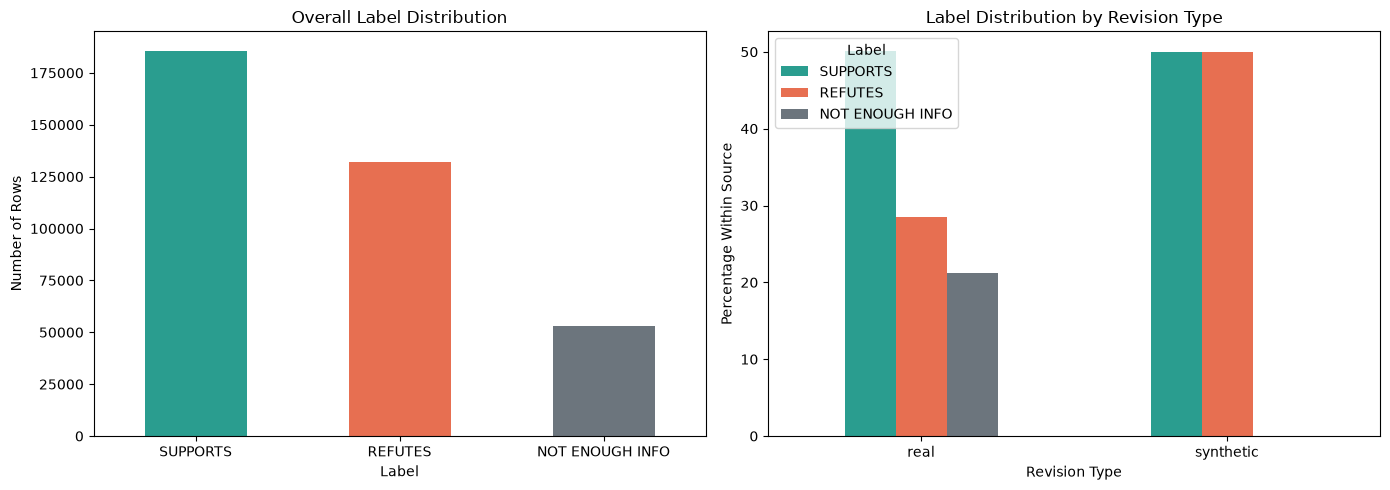

In [18]:
label_order = [
    "SUPPORTS",
    "REFUTES",
    "NOT ENOUGH INFO",
]

label_colours = {
    "SUPPORTS": "#2A9D8F",
    "REFUTES": "#E76F51",
    "NOT ENOUGH INFO": "#6C757D",
}

# Overall label distribution.
overall_label_summary = (
    vitaminc_train_df["label"]
    .value_counts()
    .reindex(label_order, fill_value=0)
    .rename_axis("label")
    .reset_index(name="rows")
)

overall_label_summary["percentage"] = (
    overall_label_summary["rows"]
    / overall_label_summary["rows"].sum()
    * 100
)

display(
    overall_label_summary.style
    .format(
        {
            "rows": "{:,}",
            "percentage": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Label distribution within each source type.
source_label_summary = (
    vitaminc_train_df
    .groupby(["revision_type", "label"])
    .size()
    .rename("rows")
    .reset_index()
)

source_label_summary["percentage_within_source"] = (
    source_label_summary["rows"]
    / source_label_summary
        .groupby("revision_type")["rows"]
        .transform("sum")
    * 100
)

display(
    source_label_summary.style
    .format(
        {
            "rows": "{:,}",
            "percentage_within_source": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Prepare plotting tables.
overall_plot = (
    overall_label_summary
    .set_index("label")
    .reindex(label_order)
)

source_percentage_plot = (
    source_label_summary
    .pivot(
        index="revision_type",
        columns="label",
        values="percentage_within_source",
    )
    .reindex(columns=label_order, fill_value=0)
    .fillna(0)
)

# Visualise overall and source-specific distributions.
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

overall_plot["rows"].plot(
    kind="bar",
    ax=axes[0],
    color=[label_colours[label] for label in label_order],
)

axes[0].set_title("Overall Label Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Number of Rows")
axes[0].tick_params(axis="x", rotation=0)

source_percentage_plot.plot(
    kind="bar",
    ax=axes[1],
    color=[label_colours[label] for label in label_order],
)

axes[1].set_title("Label Distribution by Revision Type")
axes[1].set_xlabel("Revision Type")
axes[1].set_ylabel("Percentage Within Source")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Label")

plt.tight_layout()
plt.show()

### Findings

The VitaminC training data is not evenly distributed across its three fact-verification labels.

Overall, the dataset contains:

- 185,714 `SUPPORTS` rows, approximately 50.10% of the data;
- 131,958 `REFUTES` rows, approximately 35.60%; and
- 52,981 `NOT ENOUGH INFO` rows, approximately 14.29%.

The distribution differs substantially between the two revision types.

#### Real Wikipedia Revisions

The real subset contains:

- 124,864 `SUPPORTS` rows (50.16%);
- 71,108 `REFUTES` rows (28.56%); and
- 52,981 `NOT ENOUGH INFO` rows (21.28%).

Supported examples are therefore the largest class in the real data. A model could obtain misleadingly favourable accuracy by predicting `SUPPORTED` more frequently, so overall accuracy should not be used alone.

#### Synthetic Examples

The synthetic subset is perfectly balanced between:

- 60,850 `SUPPORTS` rows (50.00%); and
- 60,850 `REFUTES` rows (50.00%).

There are no synthetic `NOT ENOUGH INFO` examples. This reflects the construction of the synthetic contrastive data rather than an accidental missing-value problem.

#### Evaluation Implications

The different source distributions mean that model results should be reported:

- overall;
- separately for real and synthetic examples;
- separately for each label; and
- using macro-averaged metrics in addition to accuracy.

For the current sensitivity experiment, the selected synthetic and real pairs compare `SUPPORTED` with `REFUTED`. Therefore, the sensitivity score measures whether the model correctly reacts to a decisive evidence change; it does not measure sensitivity involving `NOT ENOUGH INFO`.

No labels should be deleted or resampled for evaluation. If a trained classifier is added later, class weighting or stratified training may be considered using only the training split.

## Topic Coverage of Claims

VitaminC does not provide predefined subject categories. To explore the common themes in the dataset, this analysis applies TF-IDF and Non-negative Matrix Factorisation (NMF) to the unique training claims.

TF-IDF represents claims using informative words and phrases, while NMF groups claims that use similar vocabulary. The resulting topics are exploratory clusters rather than official categories. Topic names will be assigned manually after reviewing their most important terms and representative claims.

Duplicate claim texts are removed before topic modelling so that repeated evidence versions do not artificially increase a topic's frequency.

topic,unique_claims,percentage,top_terms,example_claim
Topic 1,"18,806",10.69%,"rotten, tomatoes, rotten tomatoes, reviews, rating, based, approval, approval rating, 10, average, average rating, reviews rotten",There are less than 147 reviews of Arriety on Rotten Tomatoes .
Topic 2,"15,869",9.02%,"coronavirus, cases, 2020, coronavirus cases, confirmed, march, cases coronavirus, pandemic, april, coronavirus pandemic, deaths, new",Panama has less than 8 coronavirus cases .
Topic 3,"19,230",10.93%,"film, american, critics, directed, reviews, starred, character, comedy, received, american film, drama, actor","In the film Kingpin , McCracken eluded the bowlers ."
Topic 4,"15,004",8.53%,"million, worldwide, earned, sold, million worldwide, grossed, globally, copies, million copies, america, million globally, north",Everest made over $ 159 million .
Topic 5,"10,448",5.94%,"born, 1970, july, born june, june, born july, 1990, born april, born 1970, born 1990, december, january","In 1937 , Saddam Hussein was born ."
Topic 6,"78,679",44.73%,"released, album, band, studio, song, series, rock, american, studio album, released album, music, albums",Hilltop Hoods have released one `` restrung '' album .
Topic 7,"10,708",6.09%,"united, states, united states, states canada, canada, million united, city, movie, kingdom, united kingdom, manchester, manchester united",Alfonso Ribeiro is from the United States .
Topic 8,"7,161",4.07%,"19, covid, covid 19, 19 cases, 2020, people, cases, april, cases covid, 000, march, tested","Wallis and Futuna was yet to announce COVID-19 by April 3 , 2020 ."


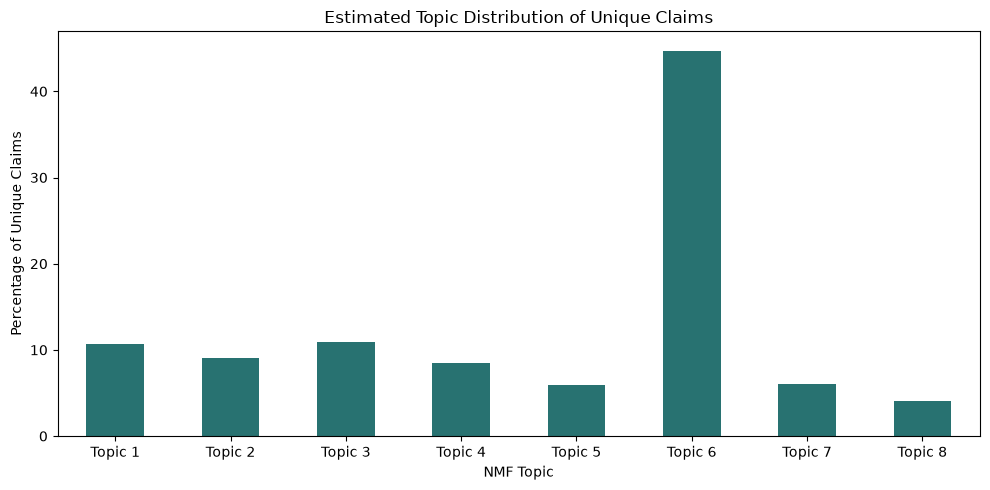

In [23]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    TfidfVectorizer,
)

# Use each exact claim only once so contrastive repetitions
# do not distort the topic distribution.
topic_claims = (
    vitaminc_train_df[["claim"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

custom_stop_words = sorted(
    set(ENGLISH_STOP_WORDS).union(
        {
            "lrb",
            "rrb",
            "lsb",
            "rsb",
            "rcb",
            "lcb",
        }
    )
)

# Convert claim text into a sparse TF-IDF representation.
topic_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=custom_stop_words,
    ngram_range=(1, 2),
    min_df=20,
    max_df=0.85,
    max_features=5000,
    sublinear_tf=True,
)

claim_tfidf = topic_vectorizer.fit_transform(
    topic_claims["claim"]
)

# Discover eight broad topics.
number_of_topics = 8

topic_model = NMF(
    n_components=number_of_topics,
    init="nndsvda",
    random_state=42,
    max_iter=300,
)

topic_weights = topic_model.fit_transform(claim_tfidf)

topic_claims["topic"] = (
    topic_weights.argmax(axis=1) + 1
)

feature_names = topic_vectorizer.get_feature_names_out()

topic_rows = []

for topic_index in range(number_of_topics):
    top_term_indices = (
        topic_model.components_[topic_index]
        .argsort()[-12:][::-1]
    )

    top_terms = [
        feature_names[index]
        for index in top_term_indices
    ]

    strongest_claim_indices = (
        topic_weights[:, topic_index]
        .argsort()[-3:][::-1]
    )

    example_claims = [
        topic_claims.iloc[index]["claim"]
        for index in strongest_claim_indices
    ]

    topic_number = topic_index + 1
    topic_count = int(
        (topic_claims["topic"] == topic_number).sum()
    )

    topic_rows.append(
        {
            "topic": f"Topic {topic_number}",
            "unique_claims": topic_count,
            "percentage": (
                topic_count / len(topic_claims) * 100
            ),
            "top_terms": ", ".join(top_terms),
            "example_claim": example_claims[0],
        }
    )

topic_summary = pd.DataFrame(topic_rows)

display(
    topic_summary.style
    .format(
        {
            "unique_claims": "{:,}",
            "percentage": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

# Plot the estimated topic distribution.
ax = topic_summary.plot(
    x="topic",
    y="percentage",
    kind="bar",
    figsize=(10, 5),
    color="#287271",
    legend=False,
)

ax.set_title("Estimated Topic Distribution of Unique Claims")
ax.set_xlabel("NMF Topic")
ax.set_ylabel("Percentage of Unique Claims")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

topic,interpreted_topic,unique_claims,percentage,top_terms,example_claim
Topic 1,Reviews and Ratings,"18,806",10.69%,"rotten, tomatoes, rotten tomatoes, reviews, rating, based, approval, approval rating, 10, average, average rating, reviews rotten",There are less than 147 reviews of Arriety on Rotten Tomatoes .
Topic 2,Coronavirus Cases,"15,869",9.02%,"coronavirus, cases, 2020, coronavirus cases, confirmed, march, cases coronavirus, pandemic, april, coronavirus pandemic, deaths, new",Panama has less than 8 coronavirus cases .
Topic 3,Film and Cinema,"19,230",10.93%,"film, american, critics, directed, reviews, starred, character, comedy, received, american film, drama, actor","In the film Kingpin , McCracken eluded the bowlers ."
Topic 4,Sales and Revenue,"15,004",8.53%,"million, worldwide, earned, sold, million worldwide, grossed, globally, copies, million copies, america, million globally, north",Everest made over $ 159 million .
Topic 5,Biographies and Birth Dates,"10,448",5.94%,"born, 1970, july, born june, june, born july, 1990, born april, born 1970, born 1990, december, january","In 1937 , Saddam Hussein was born ."
Topic 6,Music and Entertainment,"78,679",44.73%,"released, album, band, studio, song, series, rock, american, studio album, released album, music, albums",Hilltop Hoods have released one `` restrung '' album .
Topic 7,Geography and Nationality,"10,708",6.09%,"united, states, united states, states canada, canada, million united, city, movie, kingdom, united kingdom, manchester, manchester united",Alfonso Ribeiro is from the United States .
Topic 8,COVID-19 Testing and Outbreaks,"7,161",4.07%,"19, covid, covid 19, 19 cases, 2020, people, cases, april, cases covid, 000, march, tested","Wallis and Futuna was yet to announce COVID-19 by April 3 , 2020 ."


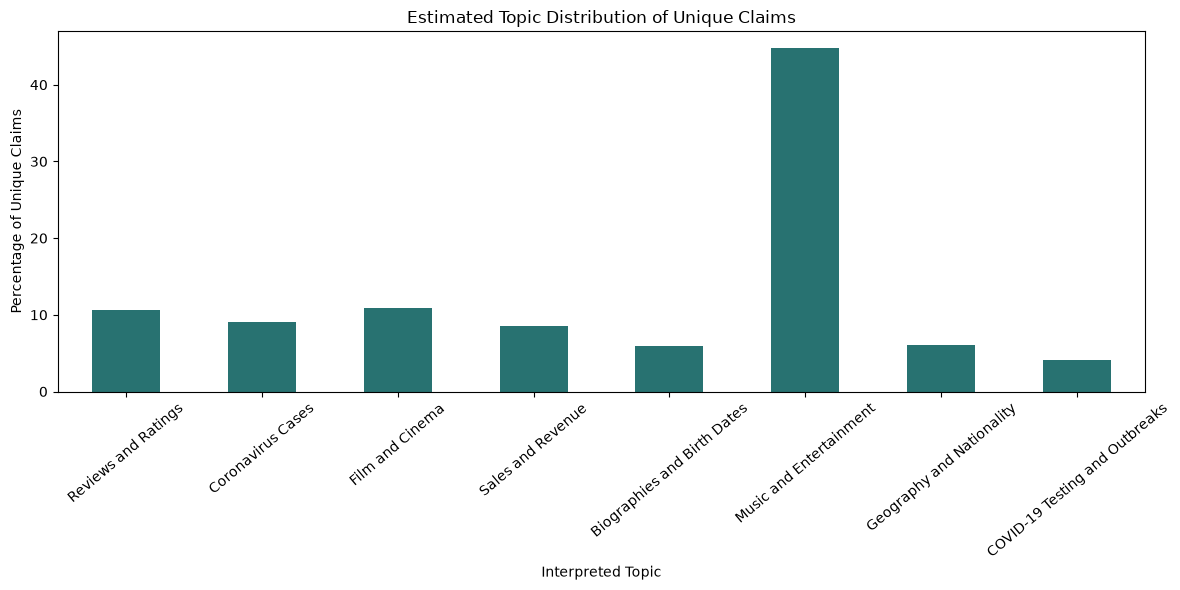

In [24]:
topic_name_map = {
    "Topic 1": "Reviews and Ratings",
    "Topic 2": "Coronavirus Cases",
    "Topic 3": "Film and Cinema",
    "Topic 4": "Sales and Revenue",
    "Topic 5": "Biographies and Birth Dates",
    "Topic 6": "Music and Entertainment",
    "Topic 7": "Geography and Nationality",
    "Topic 8": "COVID-19 Testing and Outbreaks",
}

topic_summary["interpreted_topic"] = (
    topic_summary["topic"].map(topic_name_map)
)

display_columns = [
    "topic",
    "interpreted_topic",
    "unique_claims",
    "percentage",
    "top_terms",
    "example_claim",
]

display(
    topic_summary[display_columns].style
    .format(
        {
            "unique_claims": "{:,}",
            "percentage": "{:.2f}%",
        }
    )
    .hide(axis="index")
)

ax = topic_summary.plot(
    x="interpreted_topic",
    y="percentage",
    kind="bar",
    figsize=(12, 6),
    color="#287271",
    legend=False,
)

ax.set_title("Estimated Topic Distribution of Unique Claims")
ax.set_xlabel("Interpreted Topic")
ax.set_ylabel("Percentage of Unique Claims")
ax.tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

### Findings

The topic analysis indicates that VitaminC is heavily concentrated in entertainment-related content. **Music and Entertainment** is the largest topic, representing 44.73% of unique claims. Claims about films, reviews, ratings, sales and revenue form several additional clusters, showing that media and popular culture are strongly represented.

COVID-19 is another prominent subject. Two related clusters cover coronavirus case numbers, pandemic timelines, testing and outbreak status. Other smaller themes include biographies, birth dates, geography and nationality.

A clearly defined political topic did not emerge. This does not mean political claims are absent; they may be less frequent or distributed across broader vocabulary-based clusters.

These topics were generated automatically from shared words and phrases, then manually interpreted. They are exploratory themes rather than official dataset categories, and individual claims may fit more than one topic.

Overall, the dataset provides varied subject coverage but is not domain-balanced. Because entertainment and pandemic-related claims are prominent, the final model results should not be presented as proof of equal performance across all domains.

## Text Quality and Encoding Audit

This analysis checks the claim and evidence fields for common text-quality issues, including empty text, encoding problems, Wikipedia formatting tokens, repeated whitespace, HTML and URLs.

These patterns are counted rather than automatically corrected. Any preprocessing must preserve the original factual meaning and remain consistent across all evaluated models.

In [25]:
text_quality_rows = []

quality_checks = {
    "Empty or whitespace-only text": (
        lambda text: text.str.strip().eq("")
    ),
    "Unicode replacement character": (
        lambda text: text.str.contains(
            "\uFFFD",
            regex=False,
        )
    ),
    "Wikipedia bracket tokens": (
        lambda text: text.str.contains(
            r"-(?:LRB|RRB|LSB|RSB|LCB|RCB)-",
            regex=True,
        )
    ),
    "Repeated whitespace": (
        lambda text: text.str.contains(
            r"\s{2,}",
            regex=True,
        )
    ),
    "HTML-like tags": (
        lambda text: text.str.contains(
            r"<[^>]+>",
            regex=True,
        )
    ),
    "URLs": (
        lambda text: text.str.contains(
            r"https?://|www\.",
            regex=True,
        )
    ),
    "Non-ASCII characters": (
        lambda text: text.str.contains(
            r"[^\x00-\x7F]",
            regex=True,
        )
    ),
    "Control characters": (
        lambda text: text.str.contains(
            r"[\x00-\x08\x0B\x0C\x0E-\x1F]",
            regex=True,
        )
    ),
}

for column in ["claim", "evidence"]:
    text = (
        vitaminc_train_df[column]
        .fillna("")
        .astype(str)
    )

    for check_name, check_function in quality_checks.items():
        matches = check_function(text)
        affected_rows = int(matches.sum())

        text_quality_rows.append(
            {
                "text_field": column,
                "quality_check": check_name,
                "affected_rows": affected_rows,
                "affected_percentage": (
                    affected_rows / len(text) * 100
                ),
            }
        )

text_quality_summary = pd.DataFrame(text_quality_rows)

display(
    text_quality_summary.style
    .format(
        {
            "affected_rows": "{:,}",
            "affected_percentage": "{:.3f}%",
        }
    )
    .hide(axis="index")
)

text_field,quality_check,affected_rows,affected_percentage
claim,Empty or whitespace-only text,0,0.000%
claim,Unicode replacement character,8,0.002%
claim,Wikipedia bracket tokens,0,0.000%
claim,Repeated whitespace,0,0.000%
claim,HTML-like tags,0,0.000%
claim,URLs,0,0.000%
claim,Non-ASCII characters,"10,135",2.734%
claim,Control characters,0,0.000%
evidence,Empty or whitespace-only text,0,0.000%
evidence,Unicode replacement character,"1,267",0.342%


### Findings

The claim and evidence fields are complete. There are no empty records or control characters in either field, so every row contains usable text.

A very small number of claims contain Unicode replacement characters, while 1,267 evidence passages contain them. These characters indicate that part of the original text could not be decoded correctly. The affected records should be flagged for review, but they should not be deleted automatically.

Wikipedia bracket tokens such as `-LRB-` and `-RRB-` occur in 20,918 evidence passages. These are formatting artefacts representing brackets rather than missing information. They may be converted to normal brackets for display, but the original text should be retained for reproducibility.

Repeated whitespace appears in 1.48% of evidence passages. Collapsing repeated spaces is a low-risk presentation improvement, although it is not necessary for the existing benchmark experiments.

HTML-like tags and URLs are uncommon. They may be legitimate parts of Wikipedia evidence, so they should be inspected rather than removed automatically.

Non-ASCII characters occur in 2.73% of claims and 8.34% of evidence passages. These may include accented names, non-English terms and valid symbols. Non-ASCII text is not a data-quality error and should not be stripped.

Overall, the dataset is suitable for modelling with minimal preprocessing. The raw text should remain unchanged for reproducibility. Any cleaned version used for display or future inference should be stored separately and applied consistently to every model.

In [26]:
inspection_columns = [
    "unique_id",
    "revision_type",
    "label",
    "claim",
    "evidence",
]

def sample_issue(
    dataframe,
    column,
    pattern,
    sample_size=10,
    regex=True,
):
    mask = (
        dataframe[column]
        .fillna("")
        .astype(str)
        .str.contains(pattern, regex=regex)
    )

    affected = dataframe.loc[
        mask,
        inspection_columns,
    ]

    sample_count = min(sample_size, len(affected))

    if sample_count == 0:
        return affected

    return affected.sample(
        n=sample_count,
        random_state=42,
    )

print("Claims containing replacement characters:")

display(
    sample_issue(
        vitaminc_train_df,
        column="claim",
        pattern="\uFFFD",
        sample_size=8,
        regex=False,
    )
)

print("Evidence containing replacement characters:")

display(
    sample_issue(
        vitaminc_train_df,
        column="evidence",
        pattern="\uFFFD",
        sample_size=10,
        regex=False,
    )
)

print("Evidence containing HTML-like tags:")

display(
    sample_issue(
        vitaminc_train_df,
        column="evidence",
        pattern=r"<[^>]+>",
        sample_size=10,
        regex=True,
    )
)

Claims containing replacement characters:


,unique_id,revision_type,label,claim,evidence
241,5ed7acfec9e77c00084a5860_2,real,REFUTES,"Marc Anthony�s songs Vivir Mi Vida has under 600 million views , while Flor P�lida has less than 200 million views .","Marc Anthony has had 25 Billboard chart hits � most recently , Vivir Mi Vida and Flor P�lida , which have received m..."
391,5ec7d50fc9e77c0008442fc7_2,real,NOT ENOUGH INFO,"Leatherman�s only facility is located in Portland , Oregon and assembles more than 16,000 tools per week .","By the end of 2001 , the company had sales of $ 100 million annually and had sold more than 20 million tools ."
240,5ed7acfec9e77c00084a5860_1,real,NOT ENOUGH INFO,"Marc Anthony�s songs Vivir Mi Vida has under 600 million views , while Flor P�lida has less than 200 million views .","Marc Anthony has had 25 Billboard chart hits � most recently , Vivir Mi Vida and Flor P�lida , which have received m..."
1810,5eafed7ec9e77c0009ce0c4e_2,real,SUPPORTS,26 to 28 degrees Fahrenheit equates to around -3�C,`` To photograph one scene during which expedition guide Rob Hall ( Jason Clarke ) is stuck on the mountain in the s...
242,5ed7acfec9e77c00084a5860_3,real,NOT ENOUGH INFO,"Marc Anthony�s songs Vivir Mi Vida has over 600 million views , while Flor P�lida has more than 200 million views .","Marc Anthony has had 25 Billboard chart hits � most recently , Vivir Mi Vida and Flor P�lida , which have received m..."
390,5ec7d50fc9e77c0008442fc7_1,real,SUPPORTS,"Leatherman�s only facility is located in Portland , Oregon and assembles more than 16,000 tools per week .","Today , Leatherman�s only manufacturing facility is located in Portland , Oregon where they assemble 17,000 tools pe..."
243,5ed7acfec9e77c00084a5860_4,real,SUPPORTS,"Marc Anthony�s songs Vivir Mi Vida has over 600 million views , while Flor P�lida has more than 200 million views .","Marc Anthony has had 25 Billboard chart hits � most recently , Vivir Mi Vida and Flor P�lida , which have received m..."
1809,5eafed7ec9e77c0009ce0c4e_1,real,NOT ENOUGH INFO,26 to 28 degrees Fahrenheit equates to around -3�C,`` To photograph one scene during which expedition guide Rob Hall ( Jason Clarke ) is stuck on the mountain in the s...


Evidence containing replacement characters:


,unique_id,revision_type,label,claim,evidence
32767,5eb9573cc9e77c0008fa1c43_1,real,SUPPORTS,Andy Ruiz Jr. was an 11-1 underdog before his fight against Anthony Joshua .,"After coming in as an 11�1 underdog , in a shocking upset , Ruiz Jr. won the match via technical knockout in the sev..."
30505,5eb9573bc9e77c0008fa186f_2,real,SUPPORTS,Emiliano Martinez was called up by the Argentina squad to play against Germany and Ecuador but remained an unused sub .,He was called up to the Argentina senior squad to replace �scar Ustari to face Nigeria in June 2011.. He received hi...
4402,5eafed80c9e77c0009ce114d_4,real,SUPPORTS,Shade was scheduled for release in 2016 .,"In 2013 , Living Colour performed the song live during Punk 's entrance at WrestleMania 29.On July 2 , 2014 Living C..."
31492,5eb9573bc9e77c0008fa1a0b_4,real,SUPPORTS,Djurgardens won their 8th Allsvenskan title .,"Djurg�rdens IF won the Allsvenskan title , their first since 2005 , their 8th overall and their 12th Swedish champio..."
28869,5eb95739c9e77c0008fa153b_4,real,SUPPORTS,"Tampa , Florida has more than 20 completed high-rise buildings .","Overall , there are 21�completed buildings that rise over high ."
28351,5eb95738c9e77c0008fa1431_4,real,SUPPORTS,"Pies Descalzos , from Shakira , was her first International album .","`` Soon after , she found success across Latin America with her international debut album Pies Descalzos ( 1995 ) an..."
296,5ec55991c9e77c000842de26_1,real,SUPPORTS,Mireille Mathieu has over 120 million records sold worldwide .,"She has recorded over 1200 songs in 11 languages , with more than 120�million records sold worldwide."
4273,5eafed80c9e77c0009ce1121_3,real,NOT ENOUGH INFO,Ribeiro played eight games during the Campeonato Paranaense .,"Ribeiro finished the 2012 campaign for Coxa as the club 's topscorer in S�rie A along with teammate Deivid , with ei..."
675,5eafed7ec9e77c0009ce0a2b_2,real,REFUTES,Cuco Martina played for RBC Roosendaal after 2007 .,"Born in Rotterdam , Martina played for RBC Roosendaal between 2006 and 2011 , moving to RKC Waalwijk in 2011.He made..."
6471,5eafed81c9e77c0009ce17db_3,real,REFUTES,"LSU lost more than 13 games in Louisiana , against Alabama , since 1982 .",LSU has gone 4�13�1 in games played in Louisiana since 1982 .


Evidence containing HTML-like tags:


,unique_id,revision_type,label,claim,evidence
237224,5ee39417c9e77c0008cce17c_1,real,SUPPORTS,John Connally faced a trial .,"< ref > On the strength of the defense 's prominent character witnesses , Connally was acquitted."
227228,5ee393b7c9e77c0008ccc6d7_4,real,SUPPORTS,The confirmed cases of coronavirus in New Brunswick have been more 80 and there have been over 12 recoveries .,"there have been 91 confirmed cases , 14 recoveries , and no deaths. < /onlyinclude > __TOC__"
49090,5ebe6f30c9e77c00084088ee_2,real,REFUTES,"Annually , Bandar Abbas has less than 5 inches of rainfall .",The annual rainfall is around 251 mm ( 10 in ) and the relative humidity is 66 % . < center >
152143,5ede072fc9e77c00084d31a2_3,real,NOT ENOUGH INFO,EagleBank Arena at George Mason University was previously known as Patriot Center,"Another Nobel Laureate Walter E. Williams , GMU , Department of Economics , October 14 , 2002 As of 2018 , its econo..."
73484,5ec284ffc9e77c0008417b61_4,real,SUPPORTS,"Crown Heights ' street limits are Franklin Avenue to the west , Fulton Street to the north , Ralph Avenue to the eas...",< /ref > The name was changed when Crown Street was cut through in 1916 . `` Crown Heights '' from the 1939 `` WPA G...
210682,5ee393b7c9e77c0008cccc5b_1,real,SUPPORTS,Taiwan had under 320 imported cases and fewer than 52 domestic cases of COVID-19 in 2020,< /div > Imported cases : 312 ; Locally transmitted cases : 51
127909,5ec7d50dc9e77c0008441dd3_2,real,NOT ENOUGH INFO,Members of the Congress Party made up the anti-Sikh crowd .,"The 1984 anti-Sikh riots , also known as the 1984 Sikh Massacre , was a series of pogroms < /ref > against Sikhs in ..."
96656,5ec7d50ec9e77c0008442ac0_3,real,NOT ENOUGH INFO,Patricia Routledge felt that BBC was run by '10-year-old children ' when her detective series was canned .,"ref > < /ref > She was appointed OBE in 1993 and CBE in 2004. ,"
241487,5ee39418c9e77c0008ccf2c6_4,real,SUPPORTS,"Perth is near Denpasar , Bali .","< /ref > Perth is geographically closer to both Dili , East Timor ( ) , and Denpasar , Bali ( ) , than to Sydney ( )..."
208549,5ee3932cc9e77c0008ccaa68_2,real,SUPPORTS,Rhode Island reported fewer new coronavirus cases on April 26 than the two previous days .,"April 26 : New positive cases of coronavirus per day decrease for the third consecutive day , although still higher ..."


### Findings from Manual Text Inspection

The manual inspection confirms that the text-quality issues are limited and do not justify removing records.

Only eight claim rows contain Unicode replacement characters, and these rows belong to three real Wikipedia cases. The damaged characters appear in possessive forms, accented names, punctuation and temperature units. Although the claims remain understandable, the original character cannot be recovered reliably using one universal replacement rule.

Replacement characters are more common in evidence, affecting 1,267 rows (0.342%). The inspected examples show several types of encoding loss:

- accented names, such as `�scar` and `Djurg�rdens`;
- numerical separators, such as `11�1`;
- degree symbols;
- non-breaking spaces between numbers and units; and
- accented words, such as `S�rie A`.

Most affected evidence remains understandable and retains its factual meaning. However, automatic substitution would be unsafe because the same replacement character represents different original symbols in different contexts.

The 680 evidence rows containing HTML-like text mainly contain unrendered Wikipedia markup, including reference tags, layout tags and table-of-contents markers. These tokens do not add factual meaning, but the surrounding evidence remains useful.

Based on this inspection:

- no rows should be deleted;
- non-ASCII characters should be preserved;
- replacement characters should be flagged rather than automatically corrected;
- Wikipedia and HTML-like markup may be removed only in a separate cleaned field;
- repeated whitespace may be safely normalised;
- raw claim and evidence text should remain unchanged for traceability; and
- any cleaned text used for inference must be applied consistently to every model.

Overall, the text is suitable for the project with minimal preprocessing. The identified artefacts should be documented as a minor dataset-quality limitation rather than treated as widespread corruption.

## Claim-Evidence Lexical Overlap

This analysis measures how much meaningful vocabulary is shared between each claim and its evidence.

Two measures are calculated:

- **Claim coverage:** the proportion of claim words also found in the evidence.
- **Jaccard similarity:** the proportion of shared words across the combined claim and evidence vocabulary.

Common English stop words are excluded, while numbers are retained because small numerical changes can determine whether a claim is supported or refuted.

Lexical overlap does not measure factual correctness. A refuting passage may closely resemble a claim while changing only one name, date or number. The analysis instead helps identify whether the dataset may encourage simple word-matching shortcuts.

revision_type,label,rows,mean_claim_coverage,median_claim_coverage,mean_jaccard_similarity,median_jaccard_similarity
real,NOT ENOUGH INFO,"52,981",38.02%,37.50%,17.16%,14.29%
real,REFUTES,"71,108",54.27%,55.56%,24.71%,22.22%
real,SUPPORTS,"124,864",63.98%,66.67%,29.57%,26.67%
synthetic,REFUTES,"60,850",45.91%,50.00%,15.14%,12.50%
synthetic,SUPPORTS,"60,850",66.63%,71.43%,23.94%,20.00%


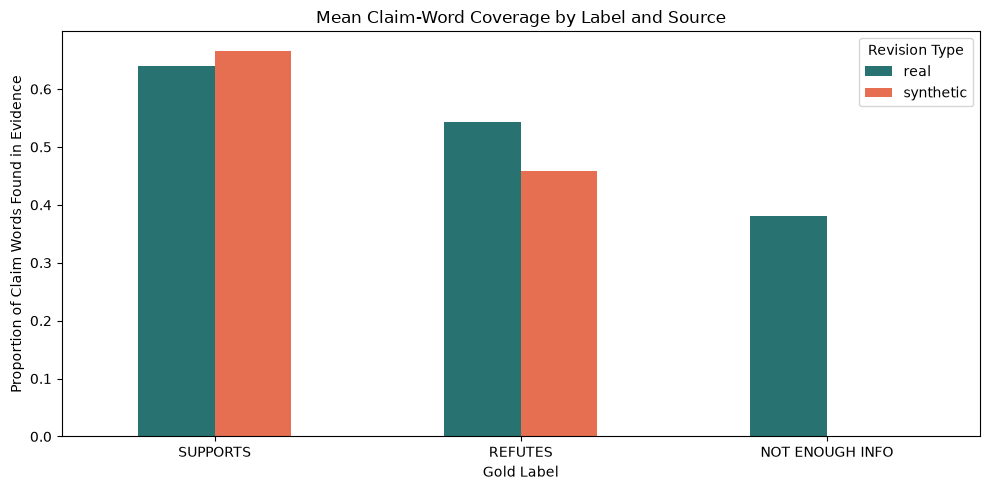

In [27]:
import re

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

token_pattern = re.compile(r"\b[a-zA-Z0-9]+\b")
stop_words = set(ENGLISH_STOP_WORDS)


def extract_content_tokens(text):
    tokens = token_pattern.findall(str(text).lower())

    return {
        token
        for token in tokens
        if token not in stop_words
        and (len(token) > 1 or token.isdigit())
    }


claim_coverage_scores = []
jaccard_scores = []

for claim, evidence in zip(
    vitaminc_train_df["claim"],
    vitaminc_train_df["evidence"],
):
    claim_tokens = extract_content_tokens(claim)
    evidence_tokens = extract_content_tokens(evidence)

    shared_tokens = claim_tokens & evidence_tokens
    combined_tokens = claim_tokens | evidence_tokens

    claim_coverage = (
        len(shared_tokens) / len(claim_tokens)
        if claim_tokens
        else float("nan")
    )

    jaccard_similarity = (
        len(shared_tokens) / len(combined_tokens)
        if combined_tokens
        else float("nan")
    )

    claim_coverage_scores.append(claim_coverage)
    jaccard_scores.append(jaccard_similarity)


lexical_overlap_df = vitaminc_train_df[
    [
        "revision_type",
        "label",
    ]
].copy()

lexical_overlap_df["claim_coverage"] = (
    claim_coverage_scores
)

lexical_overlap_df["jaccard_similarity"] = (
    jaccard_scores
)

lexical_overlap_summary = (
    lexical_overlap_df
    .groupby(["revision_type", "label"])
    .agg(
        rows=("label", "size"),
        mean_claim_coverage=("claim_coverage", "mean"),
        median_claim_coverage=("claim_coverage", "median"),
        mean_jaccard_similarity=("jaccard_similarity", "mean"),
        median_jaccard_similarity=("jaccard_similarity", "median"),
    )
    .reset_index()
)

display(
    lexical_overlap_summary.style
    .format(
        {
            "rows": "{:,}",
            "mean_claim_coverage": "{:.2%}",
            "median_claim_coverage": "{:.2%}",
            "mean_jaccard_similarity": "{:.2%}",
            "median_jaccard_similarity": "{:.2%}",
        }
    )
    .hide(axis="index")
)

coverage_plot = (
    lexical_overlap_summary
    .pivot(
        index="label",
        columns="revision_type",
        values="mean_claim_coverage",
    )
    .reindex(label_order)
)

ax = coverage_plot.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#287271", "#E76F51"],
)

ax.set_title("Mean Claim-Word Coverage by Label and Source")
ax.set_xlabel("Gold Label")
ax.set_ylabel("Proportion of Claim Words Found in Evidence")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Revision Type")

plt.tight_layout()
plt.show()

### Findings

Lexical overlap differs clearly across the three fact-checking labels.

`SUPPORTS` examples have the highest claim-word coverage. On average, 63.98% of meaningful claim words appear in real supporting evidence, rising to 66.63% in synthetic supporting evidence. This is expected because supporting passages often repeat the same entities, events and factual details as the claim.

`REFUTES` examples have lower overlap. Real refuting evidence covers 54.27% of claim words, while synthetic refuting evidence covers 45.91%. Refuting evidence may discuss the same subject but change an important name, number, date or relationship.

Real `NOT ENOUGH INFO` examples have the lowest mean claim coverage at 38.02%. This reflects that the evidence may be related to the subject without containing enough information to confirm or reject the complete claim.

The Jaccard results follow the same pattern:

```text
SUPPORTS > REFUTES > NOT ENOUGH INFO

## Qualitative Inspection of Contrastive Pairs

The quantitative checks identify valid contrastive groups, but a small manual inspection is still necessary to confirm that the pair structure is meaningful.

One real pair and one synthetic pair are selected reproducibly from the strict eligible groups. For each pair, the claim should remain exactly the same, while the evidence should change sufficiently to move the gold verdict between `SUPPORTS` and `REFUTES`.

This inspection helps verify that the numerical pairing conditions correspond to genuine fact-verification examples.

In [28]:
# Select one reproducible eligible pair from each source.
eligible_groups = contrastive_groups[
    contrastive_groups["eligible_support_refute_pair"]
].copy()

selected_pair_keys = (
    eligible_groups
    .groupby(
        "revision_type",
        group_keys=False,
    )
    .sample(
        n=1,
        random_state=42,
    )[
        [
            "case_id",
            "claim",
            "revision_type",
        ]
    ]
)

# Retrieve both rows belonging to each selected pair.
selected_pair_rows = vitaminc_train_df.merge(
    selected_pair_keys,
    on=[
        "case_id",
        "claim",
        "revision_type",
    ],
    how="inner",
)

label_sort_order = pd.CategoricalDtype(
    categories=[
        "SUPPORTS",
        "REFUTES",
    ],
    ordered=True,
)

selected_pair_rows["label"] = (
    selected_pair_rows["label"]
    .astype(label_sort_order)
)

selected_pair_rows = selected_pair_rows.sort_values(
    [
        "revision_type",
        "case_id",
        "label",
    ]
)

# Display the real and synthetic pairs separately.
for revision_type in ["real", "synthetic"]:
    pair = selected_pair_rows[
        selected_pair_rows["revision_type"]
        == revision_type
    ]

    print(
        f"{revision_type.title()} contrastive pair"
    )

    display(
        pair[
            [
                "case_id",
                "page",
                "label",
                "claim",
                "evidence",
                "wiki_revision_id",
                "FEVER_id",
            ]
        ].reset_index(drop=True)
    )

Real contrastive pair


,case_id,page,label,claim,evidence,wiki_revision_id,FEVER_id
0,5ec5598dc9e77c000842c478,Captain America-COLON- The First Avenger,SUPPORTS,The film Captain America is rated as more than 79.5 % approval rating on Rotten Tomatoes based on 253 reviews .,The review aggregator website Rotten Tomatoes reported an 80 % approval rating with an average rating of 7/10 based ...,837516378.0,NaN
1,5ec5598dc9e77c000842c478,Captain America-COLON- The First Avenger,REFUTES,The film Captain America is rated as more than 79.5 % approval rating on Rotten Tomatoes based on 253 reviews .,The review aggregator website Rotten Tomatoes reported an 79 % approval rating with an average rating of 7/10 based ...,837516378.0,NaN


Synthetic contrastive pair


,case_id,page,label,claim,evidence,wiki_revision_id,FEVER_id
0,5eeb7d40c9e77c0008d20e87,Helike,SUPPORTS,Helike is an ancient Greek City that was spared of the effects of the tsunami .,"Helike , ˈhɛlᵻkiː Ἑλίκη , pronounced , heˈlikɛː , modern , eˈlici , was an ancient Greek city that was spared by a...",NaN,53756.0
1,5eeb7d40c9e77c0008d20e87,Helike,REFUTES,Helike is an ancient Greek City that was spared of the effects of the tsunami .,"Helike -LRB- -LSB- ˈhɛlᵻkiː -RSB- Ἑλίκη , pronounced -LSB- heˈlikɛː -RSB- , modern -LSB- eˈlici -RSB- -RRB- was an...",NaN,53756.0


### Findings

The sampled pairs confirm that VitaminC is suitable for testing **evidence sensitivity**. In both examples, the claim remains unchanged while the evidence changes, causing the correct label to switch between `SUPPORTS` and `REFUTES`.

- In the real pair, a small numerical change from **80%** to **79%** reverses the correct verdict for a claim requiring an approval rating above **79.5%**. This tests whether the model carefully follows numerical evidence.
- In the synthetic pair, the evidence changes whether Helike was spared from the tsunami. The model should update its verdict based on the supplied evidence instead of relying on memorised knowledge.
- Both rows in each pair share the same `case_id`, Wikipedia page, claim and source identifier. Only the evidence and corresponding label change.
- The synthetic evidence contains FEVER formatting tokens such as `-LRB-`, `-LSB-` and `-RSB-`. These should be normalised in a processed text field while preserving the original evidence for traceability.

These examples support using `case_id + claim` as the grouping key for constructing contrastive sensitivity tests. A trustworthy fact-checker should return `SUPPORTS` for supporting evidence and change its verdict to `REFUTES` when the evidence is changed to contradict the same claim.

### Data-Audit Conclusion

The essential VitaminC exploratory data analysis is complete. The dataset has valid identifiers, reliable contrastive pairs and suitable labels for evaluating whether a fact-checking model responds correctly to meaningful evidence changes.

The next stage is to clean and preprocess the text, construct a reproducible experimental sample and save an experiment-ready dataset while retaining the original fields for traceability.

## Conclusion and Data-Readiness Decision

The VitaminC training dataset contains **370,653 records** and is suitable for developing and evaluating the evidence-sensitivity component of the fact-checking system. It combines **248,953 real Wikipedia-revision records** with **121,700 synthetic FEVER-derived records**.

The audit produced the following conclusions:

- All records have a unique identifier, claim, evidence passage, label, page and revision type.
- Missing `wiki_revision_id` and `FEVER_id` values are expected because they identify different data sources rather than indicating data loss.
- No duplicated `unique_id` values or exact duplicate claim-evidence-label records were found.
- Case identifiers, source identifiers and Wikipedia pages are internally consistent.
- The target variable is `label`, containing `SUPPORTS`, `REFUTES` and `NOT ENOUGH INFO`.
- The synthetic subset contains only `SUPPORTS` and `REFUTES`, while `NOT ENOUGH INFO` appears only in the real subset. Evaluation results should therefore also be reported separately by source and label.
- Using `case_id + claim` as the grouping key produces **131,709 strict SUPPORTS-REFUTES contrastive pairs**: 70,885 real pairs and 60,824 synthetic pairs.
- Qualitative inspection confirms that these pairs keep the claim fixed while changing the evidence and correct verdict. They are therefore appropriate for testing whether a model responds to evidence changes.
- Supporting evidence generally has greater lexical overlap with its claim than refuting or insufficient evidence. This may create lexical shortcuts, so overlap should be considered during model-error analysis.
- A small number of records contain encoding corruption, Wikipedia markup, URLs or repeated whitespace. These issues do not justify deleting complete records.

### Preprocessing Decision

The original columns and raw text will be preserved for traceability. Separate processed text fields should be created using conservative cleaning:

1. normalise whitespace;
2. convert FEVER bracket tokens such as `-LRB-` and `-RRB-`;
3. remove obvious HTML and Wikipedia markup;
4. preserve meaningful punctuation, numbers, accents and other Unicode characters;
5. flag unresolved replacement characters rather than guessing their original values; and
6. retain `case_id`, source identifiers and labels so contrastive pairs remain connected.

Overall, VitaminC is **ready for preprocessing and experimental sampling**. No further general EDA is required before moving to the data-preparation stage.